<a href="https://colab.research.google.com/github/eekshithakatragadda/WaterLeakDetection/blob/main/WaterLeakDetectionFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning-Based Water Leak Detection Using Sensor Data

**Course project notebook**

This notebook trains and evaluates three classifiers using the WDSEventDB sensor dataset:

1. Dummy Classifier (baseline)
2. Logistic Regression
3. Random Forest

The task is binary classification using the dataset's `Labels` column. According to the dataset documentation, `0` represents normal operation and `1` represents an anomalous/event sample. Within the Leakage folder, the task is to distinguish normal samples from leak-event samples.

**Important limitation:** WDSEventDB comes from a sensor-instrumented, lab-scale water-distribution testbed. Results should not be assumed to transfer directly to live municipal networks.

## 1. Dataset source

Dataset: **WDSEventDB: A real-time benchmark dataset for event diagnosis in water distribution networks**

- Official record: https://zenodo.org/records/17547955
- Repository and dataset description: https://github.com/Moazeni-s-Concise-Lab/WDSEventDB
- Licence shown on Zenodo: CC BY 4.0
- Files used: `Clean/CleanData.xlsx` and the three `Leakage/LeakEvent*.xlsx` files.

The original ZIP is uploaded below so the notebook can be rerun without relying on a fixed local folder path.

In [ ]:
# Upload the original WDSEventDB.zip when prompted.
from google.colab import files

uploaded = files.upload()
zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)

if zip_name is None:
    raise ValueError("Upload the original WDSEventDB.zip file.")

Saving WDSEventDB.zip to WDSEventDB.zip


In [ ]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

extract_dir = "/content/wdseventdb"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name) as archive:
    archive.extractall(extract_dir)

xlsx_paths = [
    Path(path) for path in
    glob.glob(os.path.join(extract_dir, "**", "*.xlsx"), recursive=True)
    if "__MACOSX" not in path and "/._" not in path
]

clean_path = next((p for p in xlsx_paths if p.name == "CleanData.xlsx"), None)
leak_paths = sorted([
    p for p in xlsx_paths
    if p.parent.name.lower() == "leakage" and p.name.startswith("LeakEvent")
])

if clean_path is None or len(leak_paths) != 3:
    raise FileNotFoundError(
        "Could not locate CleanData.xlsx and all three LeakEvent files in the uploaded ZIP."
    )

clean_df = pd.read_excel(clean_path)
leak_dfs = {
    p.name: pd.read_excel(p)
    for p in leak_paths
}

print("Clean data shape:", clean_df.shape)
print("\nLeakage event files:")
for name, df in leak_dfs.items():
    print(f"{name}: {df.shape}; labels={df['Labels'].value_counts().sort_index().to_dict()}")

print("\nClean labels:", clean_df["Labels"].value_counts().sort_index().to_dict())
print("Sensor feature count:", len([c for c in clean_df.columns if c != "Labels"]))

Clean data shape: (9743, 16)

Leakage event files:
LeakEvent1.xlsx: (1368, 16); labels={0: 540, 1: 828}
LeakEvent2.xlsx: (1385, 16); labels={0: 771, 1: 614}
LeakEvent3.xlsx: (1355, 16); labels={0: 659, 1: 696}

Clean labels: {0: 9743}
Sensor feature count: 15


## 2. Data split and preprocessing

To reduce overlap between event scenarios:

- **Training:** the first 80% of `CleanData.xlsx` plus all rows from `LeakEvent1.xlsx`
- **Validation:** all rows from `LeakEvent2.xlsx`
- **Testing:** the final 20% of `CleanData.xlsx` plus all rows from `LeakEvent3.xlsx`

The validation set is used to select a classification threshold for Logistic Regression and Random Forest. The test set is held out for final evaluation.

This split separates the leakage event files, but the clean training and test portions come from the same workbook. Because sensor readings can be temporally related, the split does not guarantee complete independence. The test result should be interpreted as performance on this particular split.

In [ ]:
TARGET = "Labels"
META = "source_file"

clean_df = clean_df.copy()
clean_df["source_file"] = "CleanData.xlsx"

# Keep the event files in a fixed, explicit order.
leak1 = leak_dfs["LeakEvent1.xlsx"].copy()
leak2 = leak_dfs["LeakEvent2.xlsx"].copy()
leak3 = leak_dfs["LeakEvent3.xlsx"].copy()

clean_cut = int(len(clean_df) * 0.8)
clean_train = clean_df.iloc[:clean_cut].copy()
clean_test = clean_df.iloc[clean_cut:].copy()

leak1["source_file"] = "LeakEvent1.xlsx"
leak2["source_file"] = "LeakEvent2.xlsx"
leak3["source_file"] = "LeakEvent3.xlsx"

train_df = pd.concat([clean_train, leak1], ignore_index=True)
val_df = leak2.copy()
test_df = pd.concat([clean_test, leak3], ignore_index=True)

feature_cols = [
    col for col in clean_df.columns
    if col not in [TARGET, META]
]

X_train = train_df[feature_cols].apply(pd.to_numeric, errors="coerce")
y_train = pd.to_numeric(train_df[TARGET], errors="coerce")

X_val = val_df[feature_cols].apply(pd.to_numeric, errors="coerce")
y_val = pd.to_numeric(val_df[TARGET], errors="coerce")

X_test = test_df[feature_cols].apply(pd.to_numeric, errors="coerce")
y_test = pd.to_numeric(test_df[TARGET], errors="coerce")

# Keep rows with valid target labels.
train_valid = y_train.notna()
val_valid = y_val.notna()
test_valid = y_test.notna()

X_train, y_train = X_train.loc[train_valid], y_train.loc[train_valid].astype(int)
X_val, y_val = X_val.loc[val_valid], y_val.loc[val_valid].astype(int)
X_test, y_test = X_test.loc[test_valid], y_test.loc[test_valid].astype(int)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTraining label counts:")
print(y_train.value_counts().sort_index())
print("\nValidation label counts:")
print(y_val.value_counts().sort_index())
print("\nTest label counts:")
print(y_test.value_counts().sort_index())

Training rows: 9162
Validation rows: 1385
Test rows: 3304

Training label counts:
Labels
0    8334
1     828
Name: count, dtype: int64

Validation label counts:
Labels
0    771
1    614
Name: count, dtype: int64

Test label counts:
Labels
0    2608
1     696
Name: count, dtype: int64


## 3. Models

The Dummy Classifier is the baseline. Logistic Regression provides a linear model for comparison, and Random Forest can learn non-linear relationships between sensor measurements and the target label.

Missing sensor values are imputed using medians learned from the training data only. Logistic Regression also uses standardisation, fitted within its pipeline.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ])
}

for model in models.values():
    model.fit(X_train, y_train)

print("All three models trained.")

All three models trained.


## 4. Threshold selection using validation data

For Logistic Regression and Random Forest, the threshold is selected by maximising class-1 F1-score on the validation set. The test set is not used to select the threshold.

The threshold search is restricted to values from 0.01 to 0.50 in increments of 0.01. The Dummy Classifier uses its standard majority-class prediction as a baseline.

In [ ]:
from sklearn.metrics import f1_score

threshold_grid = np.round(np.arange(0.01, 0.501, 0.01), 2)
selected_thresholds = {}
validation_f1 = {}

for name, model in models.items():
    if name == "Dummy baseline":
        selected_thresholds[name] = None
        validation_f1[name] = f1_score(
            y_val, model.predict(X_val), zero_division=0
        )
        continue

    val_probabilities = model.predict_proba(X_val)[:, 1]
    scores = [
        f1_score(y_val, (val_probabilities >= threshold).astype(int),
                 zero_division=0)
        for threshold in threshold_grid
    ]

    best_index = int(np.argmax(scores))
    selected_thresholds[name] = float(threshold_grid[best_index])
    validation_f1[name] = float(scores[best_index])

print("Threshold selection (validation data only):")
for name in models:
    threshold = selected_thresholds[name]
    threshold_text = "default prediction" if threshold is None else f"{threshold:.2f}"
    print(f"{name}: threshold={threshold_text}; validation F1={validation_f1[name]:.4f}")

Threshold selection (validation data only):
Dummy baseline: threshold=default prediction; validation F1=0.0000
Logistic Regression: threshold=0.01; validation F1=0.6158
Random Forest: threshold=0.01; validation F1=0.6704


## 5. Final evaluation on the held-out test set

Metrics are reported for the positive class (`Labels = 1`), alongside accuracy. The confusion matrix order is `[[TN, FP], [FN, TP]]`.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

results = []
test_predictions = {}

for name, model in models.items():
    threshold = selected_thresholds[name]

    if threshold is None:
        predictions = model.predict(X_test)
    else:
        test_probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (test_probabilities >= threshold).astype(int)

    test_predictions[name] = predictions
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    results.append({
        "Model": name,
        "Threshold": "default" if threshold is None else threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (class 1)": precision_score(y_test, predictions, zero_division=0),
        "Recall (class 1)": recall_score(y_test, predictions, zero_division=0),
        "F1-score (class 1)": f1_score(y_test, predictions, zero_division=0),
        "TN": int(cm[0, 0]),
        "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]),
        "TP": int(cm[1, 1])
    })

    print(f"\n{'=' * 55}\n{name}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)
    print("\nClassification report:")
    print(classification_report(
        y_test, predictions, labels=[0, 1],
        target_names=["Normal (0)", "Event label (1)"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)
print("\nFinal model comparison:")
display(results_df.round(4))


Dummy baseline
Confusion matrix [[TN, FP], [FN, TP]]:
[[2608    0]
 [ 696    0]]

Classification report:
                 precision    recall  f1-score   support

     Normal (0)       0.79      1.00      0.88      2608
Event label (1)       0.00      0.00      0.00       696

       accuracy                           0.79      3304
      macro avg       0.39      0.50      0.44      3304
   weighted avg       0.62      0.79      0.70      3304


Logistic Regression
Confusion matrix [[TN, FP], [FN, TP]]:
[[2608    0]
 [ 696    0]]

Classification report:
                 precision    recall  f1-score   support

     Normal (0)       0.79      1.00      0.88      2608
Event label (1)       0.00      0.00      0.00       696

       accuracy                           0.79      3304
      macro avg       0.39      0.50      0.44      3304
   weighted avg       0.62      0.79      0.70      3304


Random Forest
Confusion matrix [[TN, FP], [FN, TP]]:
[[2504  104]
 [  68  628]]

Classificat

,Model,Threshold,Accuracy,Precision (class 1),Recall (class 1),F1-score (class 1),TN,FP,FN,TP
0,Dummy baseline,default,0.7893,0.0000,0.0000,0.0000,2608,0,696,0
1,Logistic Regression,0.01,0.7893,0.0000,0.0000,0.0000,2608,0,696,0
2,Random Forest,0.01,0.9479,0.8579,0.9023,0.8796,2504,104,68,628


## 6. Visualise the model comparison

The chart compares the held-out test accuracy and positive-class F1-score. Accuracy alone is not sufficient when classes are imbalanced, so the F1-score is included.

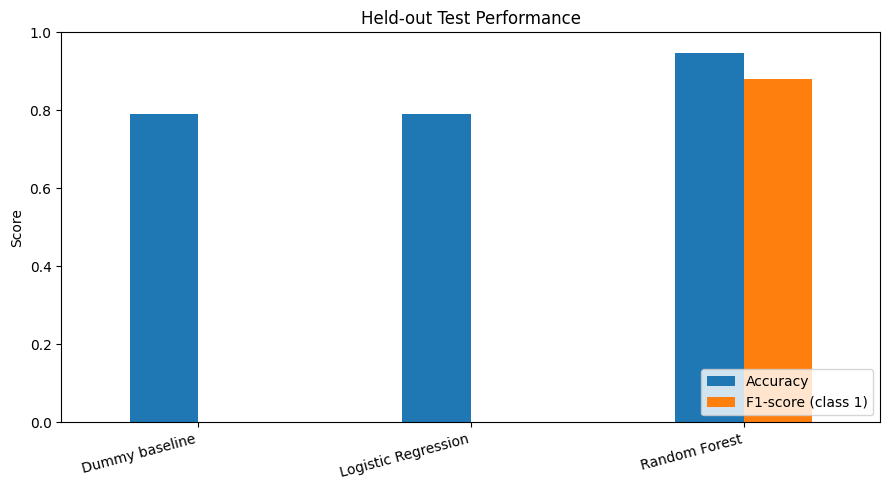

In [ ]:
plot_df = results_df.set_index("Model")[["Accuracy", "F1-score (class 1)"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
ax.set_title("Held-out Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(["Accuracy", "F1-score (class 1)"], loc="lower right")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 7. Save results

The CSV contains the metrics and confusion-matrix counts so the values in the report can be traced back to the notebook output.

In [ ]:
results_df.to_csv("model_comparison_results.csv", index=False)
print("Saved model_comparison_results.csv")

# Optional: download the CSV from Google Colab.
from google.colab import files
files.download("model_comparison_results.csv")

Saved model_comparison_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Results and interpretation

Use the metrics printed by the notebook in the final report. Do not copy expected values from another run if your own output differs.

In the current run, Random Forest performed substantially better than the Dummy baseline and Logistic Regression. Logistic Regression predicted every test sample as class 0 at its validation-selected threshold, so its class-1 precision, recall, and F1-score were zero. The Dummy baseline also predicted only the majority class.

For Random Forest, discuss both false alarms (FP) and missed event samples (FN). A high score on this test split does not prove that the model will perform equally well on other events or real municipal networks.

### Limitations

- The dataset was collected from a lab-scale water-distribution testbed.
- The selected split holds out a leakage event file, but clean training and test records come from the same workbook and may be temporally related.
- Validation uses one event file and testing uses another; sensor distributions differ between event files.
- The model distinguishes the dataset's binary normal/event labels; it does not localise a leak or estimate leak size.
- More independent events and external validation would be needed to support broader generalisation claims.

### Reproducibility checklist

- Record the Python and scikit-learn versions if required.
- Include the dataset citation and access date in the report.
- Report the exact split and threshold-selection method.
- Use the actual printed metrics and confusion matrices.
- Add related work, the research gap, motivation, and a verified reference list in the IEEE-format report.
- Disclose AI assistance according to course policy and review the final work yourself.

In [ ]:

import pandas as pd
from google.colab import files

# Upload a new dataset (CSV or Excel)
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith(".csv"):
    new_data = pd.read_csv(filename)
elif filename.lower().endswith((".xlsx", ".xls")):
    new_data = pd.read_excel(filename)
else:
    raise ValueError("Please upload a CSV or Excel file.")

# Use exactly the same sensor features used during training
X_new = new_data.reindex(columns=feature_cols)

# Convert sensor values to numbers
X_new = X_new.apply(pd.to_numeric, errors="coerce")

# Use the trained Random Forest and validation-selected threshold
rf_model = models["Random Forest"]
threshold = selected_thresholds["Random Forest"]

# Predict probabilities and classes
probabilities = rf_model.predict_proba(X_new)[:, 1]
predictions = (probabilities >= threshold).astype(int)

# Show results
results = new_data.copy()
results["Predicted_Label"] = predictions
results["Event_Probability_%"] = (probabilities * 100).round(2)

results["Prediction"] = results["Predicted_Label"].map({
    0: "Normal (0)",
    1: "Event detected (1)"
})

display(results.head(20))

# Download predictions
results.to_csv("new_dataset_predictions.csv", index=False)
files.download("new_dataset_predictions.csv")


Saving water_leak_demo_sensor_data.csv to water_leak_demo_sensor_data.csv


,Pressure 1 Out,Pressure 2 Out,Pressure 3 In,Pressure 4 In,Water Flow 1,Water Flow 2,Water Flow 3,Water Flow 4,VFD 1,VFD 2,VFD 3,VFD 4-1,VFD 4-2,Analog Valve 1,Analog Valve 2,Predicted_Label,Event_Probability_%,Prediction
0,5.120376,1.185912,1.291084,1.694224,0.422507,0.474873,0.402999,0.350293,50.805337,0.0,61.0,0.0,43.0,63.050951,65.567569,1,49.37,Event detected (1)
1,5.315565,1.353573,1.201422,1.553748,0.486811,0.453781,0.447674,0.391887,46.065556,0.0,40.0,0.0,40.0,60.367120,58.922105,1,62.79,Event detected (1)
2,5.190472,1.680227,0.863206,1.275690,0.364292,0.435541,0.321012,0.390069,39.018370,0.0,40.0,0.0,59.0,62.648137,55.585651,0,0.42,Normal (0)
3,5.504436,1.271364,1.537033,1.409179,0.473068,0.505991,0.403983,0.401721,46.698029,0.0,61.0,0.0,40.0,61.801242,56.645969,1,61.32,Event detected (1)
4,5.029782,1.732223,0.658223,1.069094,0.385771,0.410224,0.344010,0.443416,37.520493,0.0,40.0,0.0,59.0,69.841392,67.966736,1,1.37,Event detected (1)
5,5.235045,1.668656,0.943502,1.063028,0.388308,0.369194,0.296143,0.437001,38.433679,0.0,40.0,0.0,59.0,63.624289,64.813765,0,0.00,Normal (0)
6,5.056002,1.644701,1.075448,1.090015,0.366197,0.371840,0.295595,0.443930,38.101369,0.0,40.0,0.0,59.0,61.805611,62.325575,0,0.00,Normal (0)
7,5.146008,1.273781,1.285479,1.683959,0.432116,0.541969,0.439658,0.307697,45.281933,0.0,40.0,0.0,40.0,58.116569,68.190633,1,71.96,Event detected (1)
8,4.964896,1.740352,0.923750,1.344508,0.385318,0.397399,0.351014,0.482286,35.814266,0.0,40.0,0.0,59.0,60.670844,67.556133,0,0.00,Normal (0)
9,5.266777,1.324574,1.307196,1.696092,0.486061,0.450110,0.504251,0.293634,44.411522,0.0,40.0,0.0,40.0,59.056185,62.888887,1,64.84,Event detected (1)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>